<a href="https://colab.research.google.com/github/sancheznaranjoyairchayanne-design/tecnm-desarrollo-web/blob/main/laboratorios/sesion21/sesion21_laboratorio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 Sesión 21 · Fundamentos de Persistencia: SQLite / PostgreSQL y Drivers

**Desarrollo de Aplicaciones Web (DAB-2201)** · TecNM Cancún  
**Docente:** MCC. Iván Márquez Larios (`ijmarquezl`)  
**Repositorio:** https://github.com/ijmarquezl/tecnm-desarrollo-web

> **La pregunta de hoy:** ¿Qué pasa con tus datos cuando el servidor se reinicia? = Cuando el servidor se reinicia, los datos almacenados únicamente en memoria se pierden. En cambio, los datos guardados en una base de datos SQLite permanecen almacenados en el archivo biblioteca.db y pueden recuperarse cuando la aplicación vuelve a iniciar.

---

## 🖥️ Así se verá el resultado final

```text
POST /api/libros  {"titulo":"Rayuela","anio":1963}
HTTP/1.1 201 Created
{"id":1,"titulo":"Rayuela","anio":1963}

GET /api/libros
HTTP/1.1 200 OK
{"libros":[{"id":1,"titulo":"Rayuela","anio":1963}]}

$ sqlite3 biblioteca.db "SELECT id, titulo FROM libros;"
1|Rayuela

El proceso puede reiniciarse: la fila sigue en biblioteca.db.
```

_La memoria se pierde al reiniciar; el archivo de la base de datos no._

**No hay pasos intermedios.** El cuaderno declara el resultado que debe existir al final; tú decides la estructura, los modelos y el orden de tu implementación. La celda de verificación compara tu resultado con este contrato.

---

## 🎯 Al finalizar podrás

- Persistir datos en una base SQLite.
- Escribir consultas SQL parametrizadas.
- Verificar que los datos sobreviven al reinicio del proceso.

## ✅ Criterios de aceptación

El verificador ejecutará los casos HTTP y comprobará los archivos del contrato. Todo debe quedar en verde:

- [ ] La base inicia sin libros → HTTP 200
- [ ] El libro se inserta en SQLite → HTTP 201
- [ ] El listado lee la base → HTTP 200
- [ ] La fila existe en el archivo SQLite

## 🧩 El reto

Implementa un CRUD mínimo que guarde los libros en una base SQLite real, no en una lista de Python.

**Requisitos del contrato**

- La aplicación crea la tabla libros si no existe.
- POST /api/libros inserta una fila y responde 201 con el id.
- GET /api/libros lee las filas de la base y responde 200.
- Los datos quedan en el archivo biblioteca.db.
- La base se crea al iniciar la aplicación, sin pasos manuales.

> **Pista conceptual:** `sqlite3` viene incluido en Python. Crea la conexión, ejecuta el `CREATE TABLE IF NOT EXISTS` y usa `commit()` después de insertar.

## 📦 Entregable

Cuaderno en verde y bitácora `auditorias/auditoria_sesion21.md` con el esquema de la tabla.


## ⚙️ Preparación del entorno

Ejecuta esta celda una sola vez. Instala las herramientas del track **Python / FastAPI** y descarga el motor de verificación del repositorio. No necesitas instalar nada en tu computadora: todo corre en Colab.


In [2]:
import os, sys

print("⏳ Preparando el entorno de Desarrollo Web...")

!pip install -q fastapi uvicorn httpx pydantic "passlib[bcrypt]" bcrypt python-jose[cryptography] PyJWT "sqlalchemy[asyncio]" greenlet aiosqlite alembic python-multipart

!wget -q -O verificar.py https://raw.githubusercontent.com/ijmarquezl/tecnm-desarrollo-web/c275993ba69ef2a8cf650b2f127b55c8356279d7/laboratorios/verificar.py

if not os.path.exists("verificar.py") or os.path.getsize("verificar.py") < 1000:
    raise RuntimeError(
        "No se pudo descargar verificar.py. Revisa tu conexión o abre el cuaderno desde el repositorio del curso."
    )

print("✅ Entorno listo")
print("Python:", sys.version.split()[0])
print("Motor de verificación:", os.path.getsize("verificar.py"), "bytes")

⏳ Preparando el entorno de Desarrollo Web...
✅ Entorno listo
Python: 3.13.18
Motor de verificación: 13395 bytes


## 🧩 El reto: escribe el resultado

Crea el o los archivos del contrato. No hay una plantilla de pasos: el esqueleto solo te da el punto de partida. Todo lo que sigue lo decides tú.

**Archivos que debes producir:** `app.py`


### 📄 `app.py`

Archivo principal de la implementación.

In [3]:
%%writefile app.py
from fastapi import FastAPI
from pydantic import BaseModel
import sqlite3

app = FastAPI()

con = sqlite3.connect(
    "biblioteca.db",
    check_same_thread=False
)

con.execute("""
CREATE TABLE IF NOT EXISTS libros (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    titulo TEXT NOT NULL,
    anio INTEGER NOT NULL
)
""")
con.commit()


class Libro(BaseModel):
    titulo: str
    anio: int


@app.post("/api/libros", status_code=201)
def crear_libro(datos: Libro):
    cur = con.execute(
        "INSERT INTO libros (titulo, anio) VALUES (?, ?)",
        (datos.titulo, datos.anio)
    )
    con.commit()

    return {
        "id": cur.lastrowid,
        "titulo": datos.titulo,
        "anio": datos.anio
    }


@app.get("/api/libros")
def listar_libros():
    cur = con.execute(
        "SELECT id, titulo, anio FROM libros ORDER BY id"
    )

    filas = cur.fetchall()

    return {
        "libros": [
            {
                "id": fila[0],
                "titulo": fila[1],
                "anio": fila[2]
            }
            for fila in filas
        ]
    }


Writing app.py


## 🧪 Tu contrato C-R-E-O

Antes de pedir ayuda a la IA, escribe el contrato que describe el resultado. Esto alimenta tu bitácora y te obliga a pensar como arquitecto:

| Elemento | Tu definición |
| :--- | :--- |
| **Contexto** | FastAPI + Python + SQLite. La base debe crearse automáticamente al arrancar la aplicación.|
| **Rol** | Desarrollador backend especializado en APIs REST y persistencia de datos. |
| **Especificación** |GET /api/libros devuelve lista de libros (200). POST /api/libros recibe {titulo, anio}, inserta en SQLite y devuelve el registro con id (201). |
| **Output** | Respuestas JSON y persistencia en biblioteca.db. |

> No pegues código de la IA sin auditarlo. La responsabilidad técnica del resultado es tuya.


## 🔍 Verificación del resultado

Ejecuta esta celda cuando tu implementación esté lista. La verificación no modifica tu código: solo observa el comportamiento y compara con el contrato. Si algo falla, el mensaje te dice **qué esperaba** y **qué recibió**.


In [4]:
from verificar import probar_http

casos = [{'descripcion': 'La base inicia sin libros',
  'metodo': 'GET',
  'ruta': '/api/libros',
  'estado': 200,
  'json_contiene': {'libros': []}},
 {'descripcion': 'El libro se inserta en SQLite',
  'metodo': 'POST',
  'ruta': '/api/libros',
  'json': {'titulo': 'Rayuela', 'anio': 1963},
  'estado': 201,
  'json_contiene': {'id': 1, 'titulo': 'Rayuela', 'anio': 1963}},
 {'descripcion': 'El listado lee la base',
  'metodo': 'GET',
  'ruta': '/api/libros',
  'estado': 200,
  'json_contiene': {'libros': [{'id': 1, 'titulo': 'Rayuela'}]}}]

probar_http(casos, archivo="app.py", limpiar=['biblioteca.db'], env={})


VERIFICACIÓN DEL RESULTADO · 3 casos · app.py
✅ 01. La base inicia sin libros
✅ 02. El libro se inserta en SQLite
✅ 03. El listado lee la base
------------------------------------------------------------------------------
RESULTADO: 3/3 casos correctos. ¡Resultado logrado!


In [5]:
from verificar import revisar_python, resumen

resultados = []
resultados.append(revisar_python("import sqlite3\ncon = sqlite3.connect('biblioteca.db')\nfilas = con.execute('SELECT titulo FROM libros').fetchall()\nassert filas, 'la tabla libros está vacía'\nassert filas[0][0] == 'Rayuela', filas", "La fila existe en el archivo SQLite"))
resumen(resultados)


✅ La fila existe en el archivo SQLite
------------------------------------------------------------------------------
RESULTADO: 1/1 comprobaciones correctas. ¡Resultado logrado!


## 📝 Cierre y bitácora

1. Copia la plantilla `plantillas/auditoria_sesion21.md` a `auditorias/auditoria_sesion21.md` en tu fork.
2. Responde con tus palabras:
   - ¿Qué resultado te costó más alcanzar y por qué? =  El resultado más difícil fue lograr que los datos permanecieran después del reinicio, porque inicialmente se almacenaban en memoria.
   - ¿Qué decisión de diseño tomaste que no estaba escrita en el contrato? = Decidí crear la tabla automáticamente usando CREATE TABLE IF NOT EXISTS al iniciar la aplicación.
   - ¿Qué error detectó la verificación que tú no habías previsto? = La verificación permitió detectar si la fila realmente se guardaba en el archivo biblioteca.db y no solamente en memoria.
3. Haz commit de tu cuaderno ejecutado y de tu bitácora.

**La sesión termina cuando el resultado está en verde, no cuando el código "parece funcionar".**
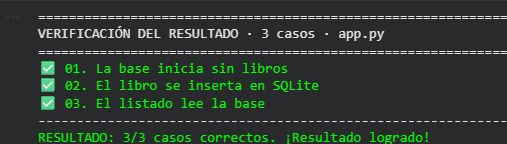
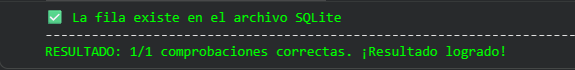